### Homework 10 ###

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from scipy.linalg import expm

from qiskit import QuantumCircuit
from qiskit.circuit.library import QFT
from qiskit.quantum_info import Operator, Statevector
from qiskit_ibm_runtime import SamplerV2 as Sampler

#### Starting in |0>

In [22]:
# Define constants
omega = 1.0
t = 2 * np.pi # Convenient choice

# Pauli-Z Hamiltonian
Z = np.array ([[1 , 0],[0 , -1]])

H = (omega / 2) * Z

# Time evolution operator
U = Operator(expm(-1j * H * t))

In [23]:
# Eigenvalues and eigenvectors ( for reference )
eigvals, eigvecs = np.linalg.eigh(H)
eigvals, eigvecs

(array([-0.5,  0.5]),
 array([[0., 1.],
        [1., 0.]]))

In [24]:
num_counting_qubits = 3
# Number of qubits used to store the phase .
# This gives a phase precision of 1 / 2^3 = 1/8 ,
# meaning QPE can resolve the phase only up to multiples of 1/8.

num_system_qubits = 1

In [25]:
qc = QuantumCircuit(num_counting_qubits + num_system_qubits)

counting = list(range(num_counting_qubits))
# Indices of the counting ( control ) qubits .
# These qubits store the binary digits of the phase $ \ phi$ measured by QPE .
# For num_counting_qubits = 3 , this corresponds to qubits [0 , 1 , 2].

system = [num_counting_qubits]
# Index of the system ( target ) qubit .
# This qubit holds the eigenstate of the Hamiltonian and is acted on by U .
# It comes immediately after the counting register in the circuit.

print(counting, system)

[0, 1, 2] [3]


In [26]:
qc.x(system[0]) # |1 > is an eigenstate of Z
# qc.id(system[0]) # |0 > is an eigenstate of Z
# qc.h(system[0]) # Prepares (|0 > + |1 >) / sqrt (2)

In [27]:
qc.h(counting)
# Apply a Hadamard gate to each counting qubit .
# This prepares the counting register in an equal superposition of all computational
# basis states , which is necessary for encoding the phase information .
# Without this superposition , QPE would not be able to extract the phase .

In [28]:
from qiskit.circuit.library import UnitaryGate

U_gate = UnitaryGate(U)
for i, qubit in enumerate(counting):
    power = 2 ** i
    controlled_U = U_gate.power(power).control()
    qc.append(controlled_U, [qubit] + system)

In [29]:
from qiskit.circuit.library import QFTGate

# The . inverse () method is used to get the Inverse QFT
qft_inv_gate = QFTGate(num_counting_qubits).inverse()
qc.append(qft_inv_gate, counting)

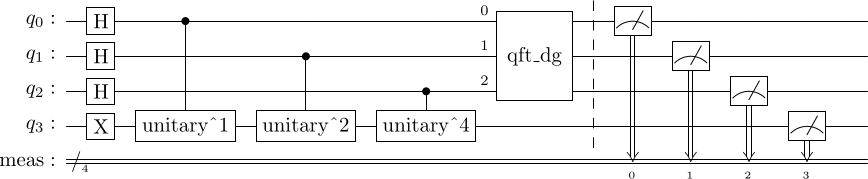

In [30]:
qc.measure_all()
qc.draw('latex')

In [31]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
job = sampler.run([qc], shots =2048)
result = job.result()
pub_result = result[0]
counts = pub_result.data.meas.get_counts()

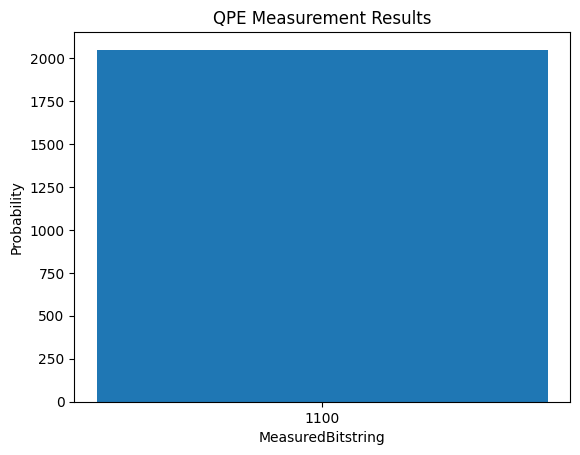

In [32]:
plt.bar (counts.keys(), counts.values())
plt.xlabel ("MeasuredBitstring")
plt.ylabel("Probability")
plt.title("QPE Measurement Results")
plt.show()

In [33]:
# Energy Estimation Logic / only for initial |1 >
bitstring = max(counts, key = counts.get)
phase_decimal = int(bitstring, 2) / (2 ** num_counting_qubits )

# Mapping phase to Energy : E = -(2 * pi * phase ) / t
# We use the negative because U = exp ( - iHt )
estimated_energy = -(2 * np.pi * phase_decimal) / t

# Handle periodicity ( phases are mod 1 , energies are mod 2 pi / t )
if estimated_energy <= -1.0:
    estimated_energy += 1.0

print(f"Most Probable Bitstring: { bitstring }")
print(f"Exact eigenvalues: { eigvals }")
print(f"Estimated energy from QPE: { estimated_energy }")

Most Probable Bitstring: 1100
Exact eigenvalues: [-0.5  0.5]
Estimated energy from QPE: -0.5


In [34]:
print ("Exact eigenvalues: " , eigvals)
print ("Estimated energy from QPE: " , estimated_energy)

Exact eigenvalues:  [-0.5  0.5]
Estimated energy from QPE:  -0.5


#### Starting in |1>

[0, 1, 2] [3]


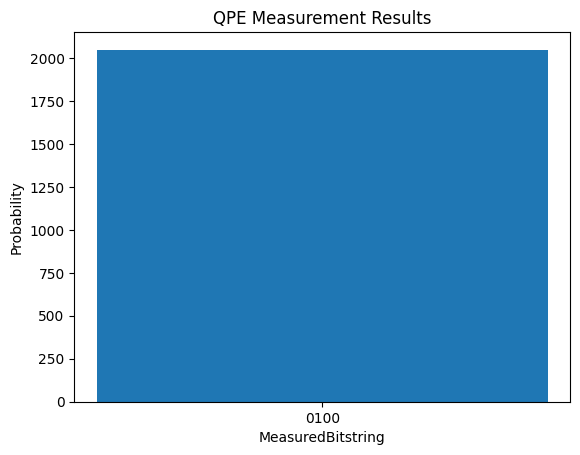

Most Probable Bitstring: 0100
Exact eigenvalues: [-0.5  0.5]
Estimated energy from QPE: -0.5
Exact eigenvalues:  [-0.5  0.5]
Estimated energy from QPE:  -0.5


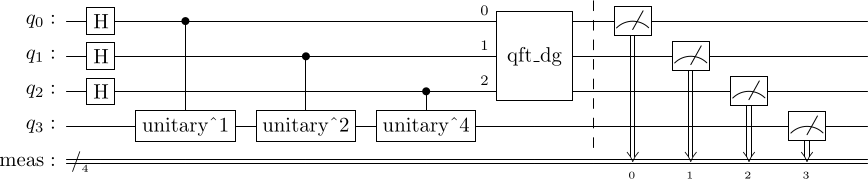

In [41]:
# Define constants
omega = 1.0
t = 2 * np.pi # Convenient choice

# Pauli-Z Hamiltonian
Z = np.array ([[1 , 0],[0 , -1]])

H = (omega / 2) * Z

# Time evolution operator
U = Operator(expm(-1j * H * t))
# Eigenvalues and eigenvectors ( for reference )
eigvals, eigvecs = np.linalg.eigh(H)
eigvals, eigvecs
num_counting_qubits = 3
# Number of qubits used to store the phase .
# This gives a phase precision of 1 / 2^3 = 1/8 ,
# meaning QPE can resolve the phase only up to multiples of 1/8.

num_system_qubits = 1
qc = QuantumCircuit(num_counting_qubits + num_system_qubits)

counting = list(range(num_counting_qubits))
# Indices of the counting ( control ) qubits .
# These qubits store the binary digits of the phase $ \ phi$ measured by QPE .
# For num_counting_qubits = 3 , this corresponds to qubits [0 , 1 , 2].

system = [num_counting_qubits]
# Index of the system ( target ) qubit .
# This qubit holds the eigenstate of the Hamiltonian and is acted on by U .
# It comes immediately after the counting register in the circuit.

print(counting, system)

# qc.x(system[0]) # |1 > is an eigenstate of Z
# qc.id(system[0]) # |0 > is an eigenstate of Z
# qc.h(system[0]) # Prepares (|0 > + |1 >) / sqrt (2)
qc.h(counting)
# Apply a Hadamard gate to each counting qubit .
# This prepares the counting register in an equal superposition of all computational
# basis states , which is necessary for encoding the phase information .
# Without this superposition , QPE would not be able to extract the phase .
from qiskit.circuit.library import UnitaryGate

U_gate = UnitaryGate(U)
for i, qubit in enumerate(counting):
    power = 2 ** i
    controlled_U = U_gate.power(power).control()
    qc.append(controlled_U, [qubit] + system)
from qiskit.circuit.library import QFTGate

# The . inverse () method is used to get the Inverse QFT
qft_inv_gate = QFTGate(num_counting_qubits).inverse()
qc.append(qft_inv_gate, counting)
qc.measure_all()
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
job = sampler.run([qc], shots =2048)
result = job.result()
pub_result = result[0]
counts = pub_result.data.meas.get_counts()
plt.bar (counts.keys(), counts.values())
plt.xlabel ("MeasuredBitstring")
plt.ylabel("Probability")
plt.title("QPE Measurement Results")
plt.show()
# Energy Estimation Logic / only for initial |1 >
bitstring = max(counts, key = counts.get)
phase_decimal = int(bitstring, 2) / (2 ** num_counting_qubits )

# Mapping phase to Energy : E = -(2 * pi * phase ) / t
# We use the negative because U = exp ( - iHt )
estimated_energy = -(2 * np.pi * phase_decimal) / t

# Handle periodicity ( phases are mod 1 , energies are mod 2 pi / t )
if estimated_energy <= -1.0:
    estimated_energy += 1.0

print(f"Most Probable Bitstring: { bitstring }")
print(f"Exact eigenvalues: { eigvals }")
print(f"Estimated energy from QPE: { estimated_energy }")
print ("Exact eigenvalues: " , eigvals)
print ("Estimated energy from QPE: " , estimated_energy)
qc.draw('latex')

#### Starting 1\sqrt{2}(|0> + |1>)

[0, 1, 2] [3]


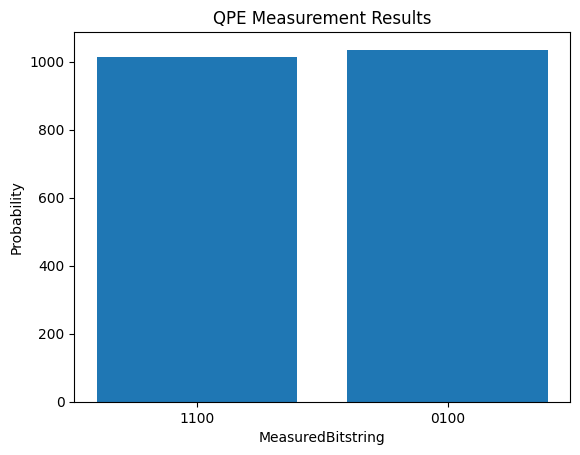

Most Probable Bitstring: 0100
Exact eigenvalues: [-0.5  0.5]
Estimated energy from QPE: -0.5
Exact eigenvalues:  [-0.5  0.5]
Estimated energy from QPE:  -0.5


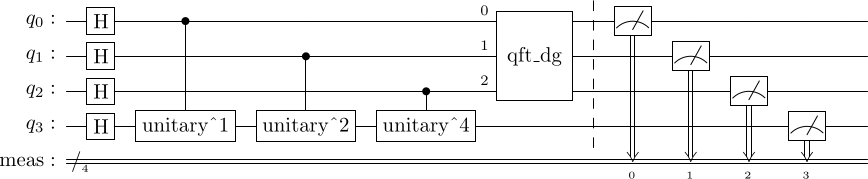

In [42]:
# Define constants
omega = 1.0
t = 2 * np.pi # Convenient choice

# Pauli-Z Hamiltonian
Z = np.array ([[1 , 0],[0 , -1]])

H = (omega / 2) * Z

# Time evolution operator
U = Operator(expm(-1j * H * t))
# Eigenvalues and eigenvectors ( for reference )
eigvals, eigvecs = np.linalg.eigh(H)
eigvals, eigvecs
num_counting_qubits = 3
# Number of qubits used to store the phase .
# This gives a phase precision of 1 / 2^3 = 1/8 ,
# meaning QPE can resolve the phase only up to multiples of 1/8.

num_system_qubits = 1
qc = QuantumCircuit(num_counting_qubits + num_system_qubits)

counting = list(range(num_counting_qubits))
# Indices of the counting ( control ) qubits .
# These qubits store the binary digits of the phase $ \ phi$ measured by QPE .
# For num_counting_qubits = 3 , this corresponds to qubits [0 , 1 , 2].

system = [num_counting_qubits]
# Index of the system ( target ) qubit .
# This qubit holds the eigenstate of the Hamiltonian and is acted on by U .
# It comes immediately after the counting register in the circuit.

print(counting, system)
# qc.x(system[0]) # |1 > is an eigenstate of Z
# qc.id(system[0]) # |0 > is an eigenstate of Z
qc.h(system[0]) # Prepares (|0 > + |1 >) / sqrt (2)
qc.h(counting)
# Apply a Hadamard gate to each counting qubit .
# This prepares the counting register in an equal superposition of all computational
# basis states , which is necessary for encoding the phase information .
# Without this superposition , QPE would not be able to extract the phase .
from qiskit.circuit.library import UnitaryGate

U_gate = UnitaryGate(U)
for i, qubit in enumerate(counting):
    power = 2 ** i
    controlled_U = U_gate.power(power).control()
    qc.append(controlled_U, [qubit] + system)
from qiskit.circuit.library import QFTGate

# The . inverse () method is used to get the Inverse QFT
qft_inv_gate = QFTGate(num_counting_qubits).inverse()
qc.append(qft_inv_gate, counting)
qc.measure_all()
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
job = sampler.run([qc], shots =2048)
result = job.result()
pub_result = result[0]
counts = pub_result.data.meas.get_counts()
plt.bar (counts.keys(), counts.values())
plt.xlabel ("MeasuredBitstring")
plt.ylabel("Probability")
plt.title("QPE Measurement Results")
plt.show()
# Energy Estimation Logic / only for initial |1 >
bitstring = max(counts, key = counts.get)
phase_decimal = int(bitstring, 2) / (2 ** num_counting_qubits )

# Mapping phase to Energy : E = -(2 * pi * phase ) / t
# We use the negative because U = exp ( - iHt )
estimated_energy = -(2 * np.pi * phase_decimal) / t

# Handle periodicity ( phases are mod 1 , energies are mod 2 pi / t )
if estimated_energy <= -1.0:
    estimated_energy += 1.0

print(f"Most Probable Bitstring: { bitstring }")
print(f"Exact eigenvalues: { eigvals }")
print(f"Estimated energy from QPE: { estimated_energy }")
print ("Exact eigenvalues: " , eigvals)
print ("Estimated energy from QPE: " , estimated_energy)
qc.draw('latex')

1. Why must the system register contain an eigenstate?
    - If the input is an eigenstate, there is one definite phase and one definite energy. If the input is a superposition, QPE does not return a new averaged energy; it returns one of the component eigenvalues probabilistically after measurement.
2. How does the number of counting qubits affect precision?
    - Increasing the number of bits increases the presision by increasing the phase resolution, which is 2^{-n}, where this resolution is the smallest difference the algorithm can detect.

3. What role does the inverse QFT play?
    - It converts relative phases into computational-basis amplitudes that can be measured, without the inverse QFT, the output would look like random noise

4. Why do controlled unitaries limit NISQ feasibility?
    - They are costly, deep and noisy. Controlled unitaries are expensive along with long coherence times.